This is a rocketpy jupyter notebook

First thing we do is import from rocketpy the following classes:

Environment, which configures the launch location and weather conditions of the selected date
Motor, which allows us to specify the geomtrical and performance characteristic of the solid rocket motor
Rocket, which allows us to specify the geomtry of the rocket, inertial characteristics and configuration of aerodynamic surfaces

In [156]:
from rocketpy import Environment, SolidMotor, Rocket, Flight

First we configure our environment.

I chose the EuRoC launchpad which is located at Campo Militar de Santa Margarida in Portugal.
Coordinates in decimal form are: 39.433333deg (North), 8.297000deg (West), 36m (Above Sea Level).

We also import datetime and pass tomorrow as the launchdate

Rocketpy automatically finds a weather forecast and can model the atmopsheric conditions at the time of launch on that day.


Gravity Details

Acceleration of gravity at surface level:    9.8008 m/s²
Acceleration of gravity at  78.257 km (ASL): 9.5641 m/s²


Launch Site Details

Launch Date: 2026-11-07 12:00:00 UTC
Launch Site Latitude: 39.43333°
Launch Site Longitude: -8.29700°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 44008.11 W    4378275.39 N
Launch Site UTM zone: 30S
Launch Site Surface Elevation: 141.6 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.257 km
Forecast Time Period: from 2026-10-30 03:00:00 to 2026-11-22 06:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 2.80 m/s
Surface Wind Direction: 96.81°
Surface Wind Heading: 276.81°
Surface Pressure: 1000.00 hPa
Surface Temperature: 286.64 K
Surface Air Density: 1.215 kg/m³
Surface Speed of Sound: 339.40 m/s


Earth Model Details

Earth Radius at Launch sit

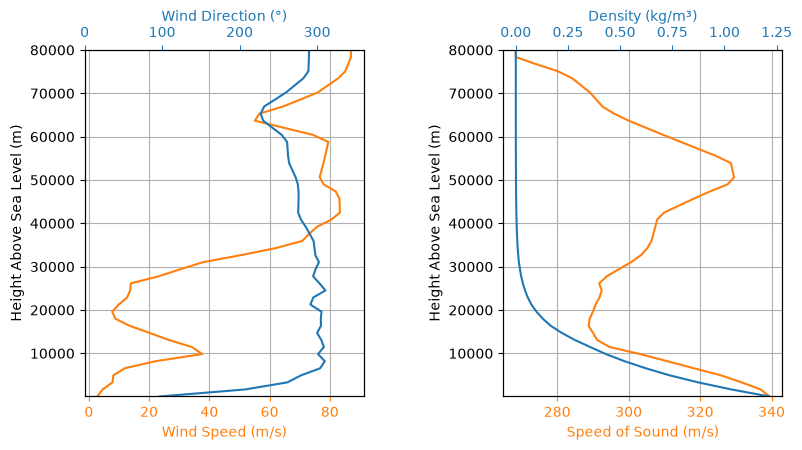

In [157]:
env = Environment(latitude=39.433333, longitude=-8.297000, elevation=36)

import datetime

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)  # Hour given in UTC time

env.set_atmospheric_model(type="Forecast", file="GFS")
env.info()     # Prints all available information about the environment

After the environment setup, we configure our rocket's SolidMotor

RocketPy allows us to use manufacturer data and use actual test curves generated from ground tests.

The thrust source is the path to the testcurve file for the motor we are using
Dry mass is the weight of the rocket motor with no fuel in it
Dry inertia is the rocket's moment of inertia in (pitch, yaw, roll) and is passed as a tuple
The grain number refers to how many individual grains (fuel units) are inside the solid rocket motor
The coordinate system defines where the origin of the rocket motor is, tail or head

Nozzle Details
Nozzle Radius: 0.035 m
Nozzle Throat Radius: 0.01 m

Grain Details
Number of Grains: 5
Grain Spacing: 0.005 m
Grain Density: 1815 kg/m3
Grain Outer Radius: 0.035 m
Grain Inner Radius: 0.01 m
Grain Height: 0.065 m
Grain Volume: 0.000 m3
Grain Mass: 0.417 kg

Motor Details
Total Burning Time: 3.47 s
Total Propellant Mass: 2.085 kg
Structural Mass Ratio: 0.513
Average Propellant Exhaust Velocity: 2423.689 m/s
Average Thrust: 1456.162 N
Maximum Thrust: 1704.286 N at 1.42 s after ignition.
Total Impulse: 5052.884 Ns



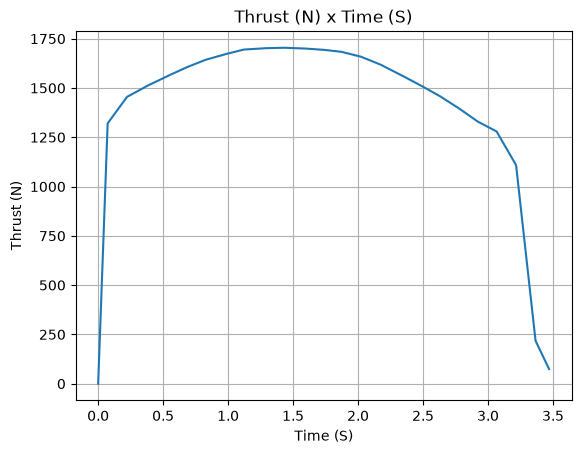

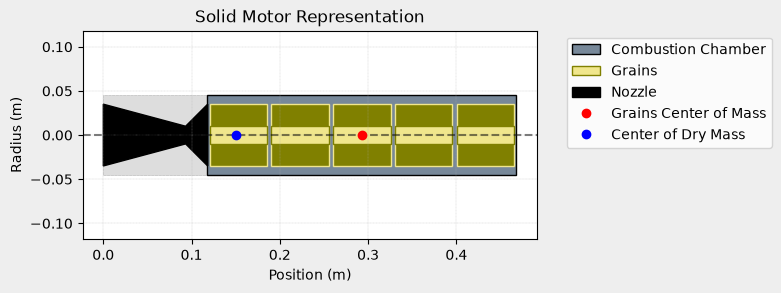

In [158]:
aerotechL1500T = SolidMotor(
    thrust_source="data/motors/AeroTech_L1500T.eng",
    dry_mass=2.1952,
    dry_inertia=(0.125, 0.125, 0.002),
    center_of_dry_mass_position=0.15,
    grains_center_of_mass_position=0.293,
    burn_time=3.47,
    grain_number=5,
    grain_separation=5 / 1000,
    grain_density=1815,
    grain_outer_radius= 0.035,
    grain_initial_inner_radius=0.01,
    grain_initial_height=0.065,
    nozzle_radius=0.035,
    throat_radius=0.01,
    interpolation_method="linear",
    nozzle_position=0,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

aerotechL1500T.info()
aerotechL1500T.draw()

After the motor setup we finally configure the rocket's geometry.
proto1 is the name of the rocket and we initially define the maximum radius, its mass and its inertia in three axis just like the motor case.
power off and power on drag refer are csv files that contain points on curves used for drag calculations. These can be generated using Computer Fluid Software (CFS). These curves define the change in drag coefficient in relation to the mach number. We use different curves because the exhaust gas reduces the drag of the induced vorticies.

Once again we define a coordinate system sticking to the tail to head convention.

After the rocket's body is configured we add aerodynamic surfaces. We chose the shape of the nose cone (von karman) and it position indicates the position of its tip in our coordinate system.

The tail fins are defined as trapezoidal fins. The root chord defines the length of the fin connected to the body of the rocket
The tip chord is the smallest length of the fin
The position shows where the highest point of the fin ends
The cant angle shows how much the fin twist
The sweep length shows how much we displace the tip chord relative to the coordinate system

Rail buttons are the loops where the launch rail passes through and we position them on the body of the rocket

The tail is a tapering part of the rocket and we define its big and small radius and its length

The parachute is defined as shown and we select its trigger to be the apogee (highest point in flight)

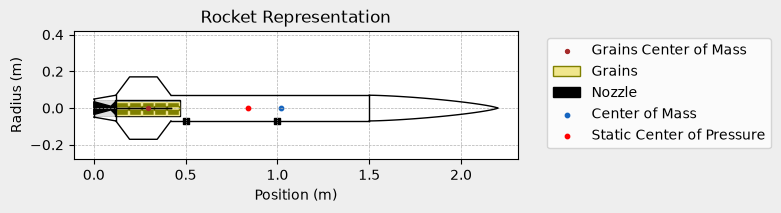

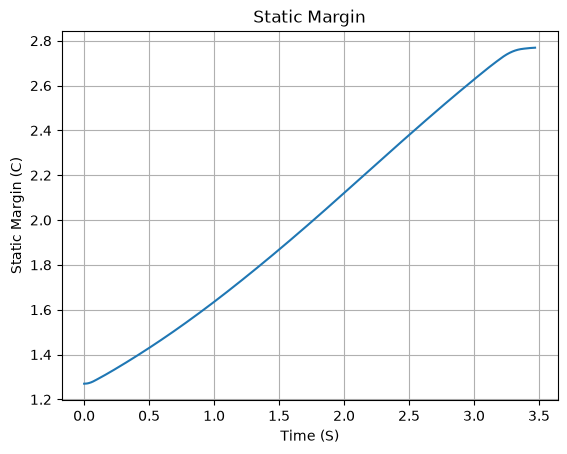

In [159]:
proto1 = Rocket(
    radius=0.07,
    mass=5,
    inertia=(2.321, 2.321, 0.024),
    power_off_drag="data/default_drag_curve.csv",
    power_on_drag="data/default_drag_curve.csv",
    center_of_mass_without_motor=1.7,
    coordinate_system_orientation="tail_to_nose",
)

nose_cone = proto1.add_nose(
    length=0.7, kind="von karman", position=2.2
)

tail_fins = proto1.add_trapezoidal_fins(
    n=4,
    root_chord=0.30,
    tip_chord=0.15,
    span=0.1,
    position=0.42,
    cant_angle=0,
    sweep_length=0.075,
    radius=None,
    airfoil=None
)

rail_buttons = proto1.set_rail_buttons(
    upper_button_position=1.0,
    lower_button_position=0.5,
    angular_position=45,
)

tail_taper = proto1.add_tail(
    top_radius=0.07, bottom_radius=0.049, length=0.12, position=0.12
)

main_chute = proto1.add_parachute(
    name="main",
    cd_s=10.0,
    trigger="apogee",
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1,
    height=1.5,
    porosity=0.0432,
)

proto1.add_motor(aerotechL1500T, position=0)
proto1.draw()
proto1.plots.static_margin()


We see the rocket's sketch and the static margin as propellent gets expended. As the fuel is consumed the center of mass moves higher up and further from the static center of pressure increasing the stability of our rocket. A rocket with a negative stability margin will not fly

We define test_flight which is takes the environment and configured rocket plus some launchpad and simulation parameters and simulates the flight using numerical integration.

We can observe the flight path in 3D as well as flight duration and maximum values during flight.

Rocketpy also graphs how the rocket "wobbles" during flight and its angular velocity in every direction.


Maximum Values

Maximum Speed: 413.101 m/s at 3.24 s
Maximum Mach Number: 1.218 Mach at 3.24 s
Maximum Reynolds Number: 3.630e+06 at 3.22 s
Maximum Dynamic Pressure: 9.516e+04 Pa at 3.22 s
Maximum Acceleration During Motor Burn: 175.124 m/s² at 1.11 s
Maximum Gs During Motor Burn: 17.858 g at 1.11 s
Maximum Acceleration After Motor Burn: 149.319 m/s² at 23.32 s
Maximum Gs After Motor Burn: 15.226 Gs at 23.32 s
Maximum Stability Margin: 2.879 c at 3.66 s
Maximum Upper Rail Button Normal Force: 0.250 N
Maximum Upper Rail Button Shear Force: 2.100 N
Maximum Lower Rail Button Normal Force: 0.453 N
Maximum Lower Rail Button Shear Force: 3.807 N

Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 141.59 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.923 | e1: -0.040 | e2: 0.017 | e3: 0.382
Euler Angles - Spin φ : 45.00° | Nutation θ: -5.00° | Precession ψ: 0.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00

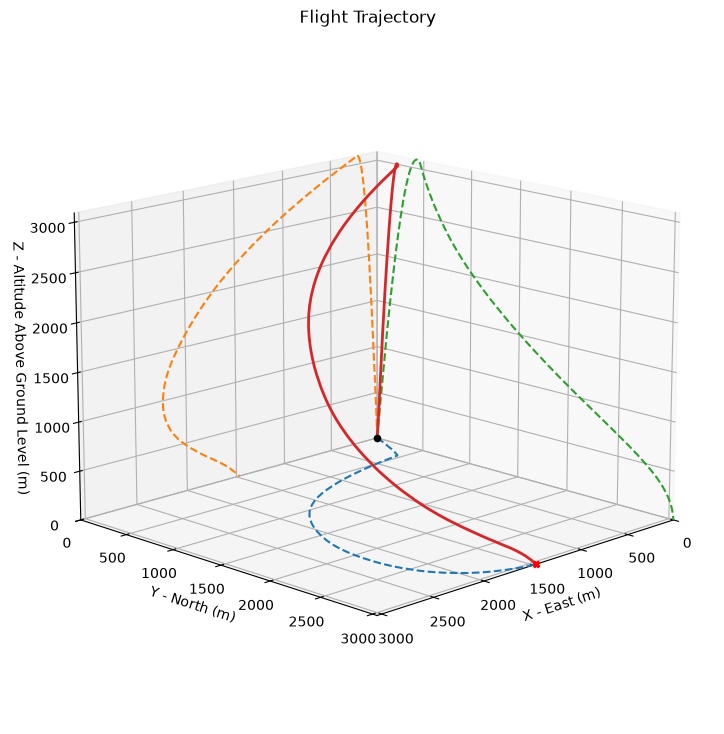



Trajectory Kinematic Plots



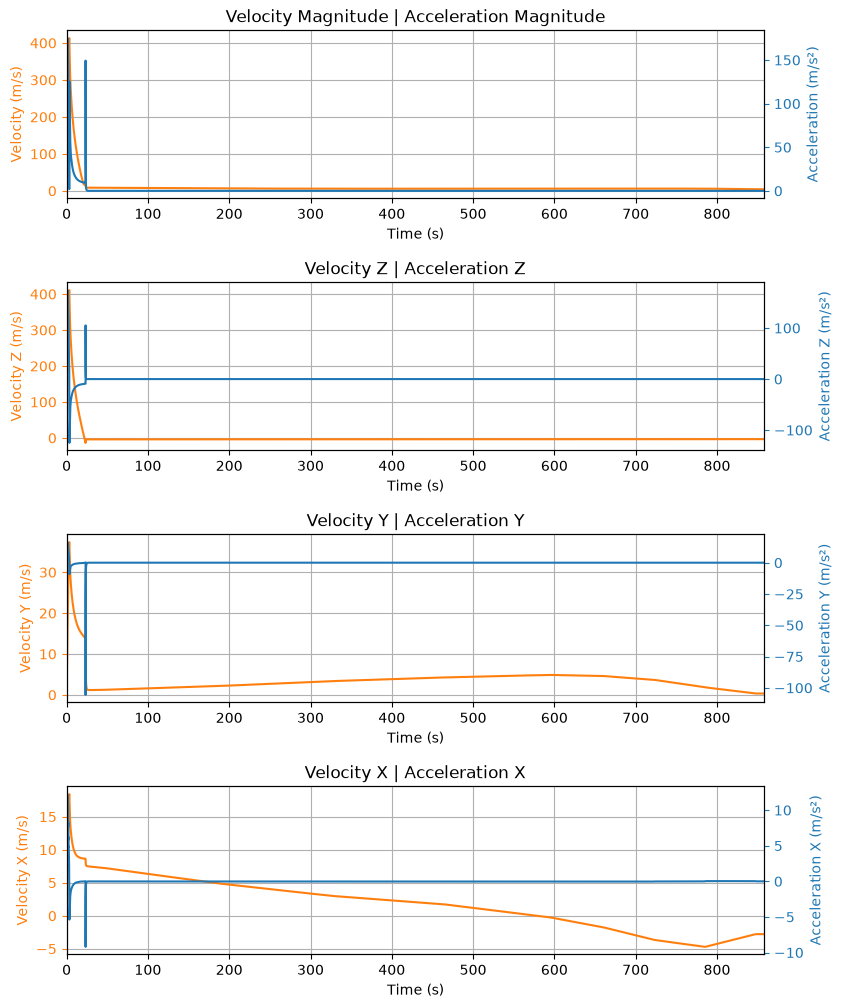



Angular Position Plots



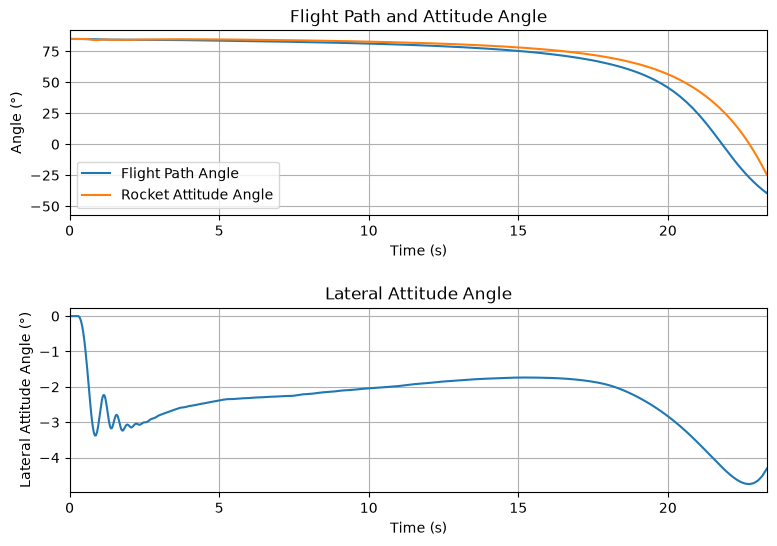



Path, Attitude and Lateral Attitude Angle Plots



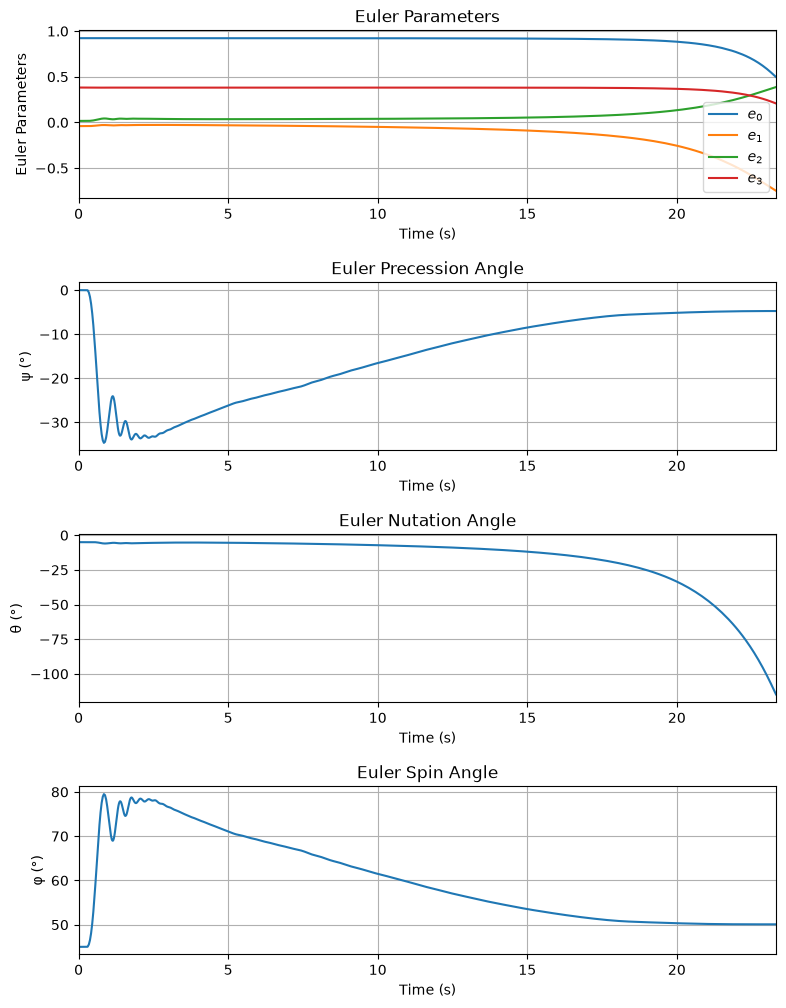



Trajectory Angular Velocity and Acceleration Plots



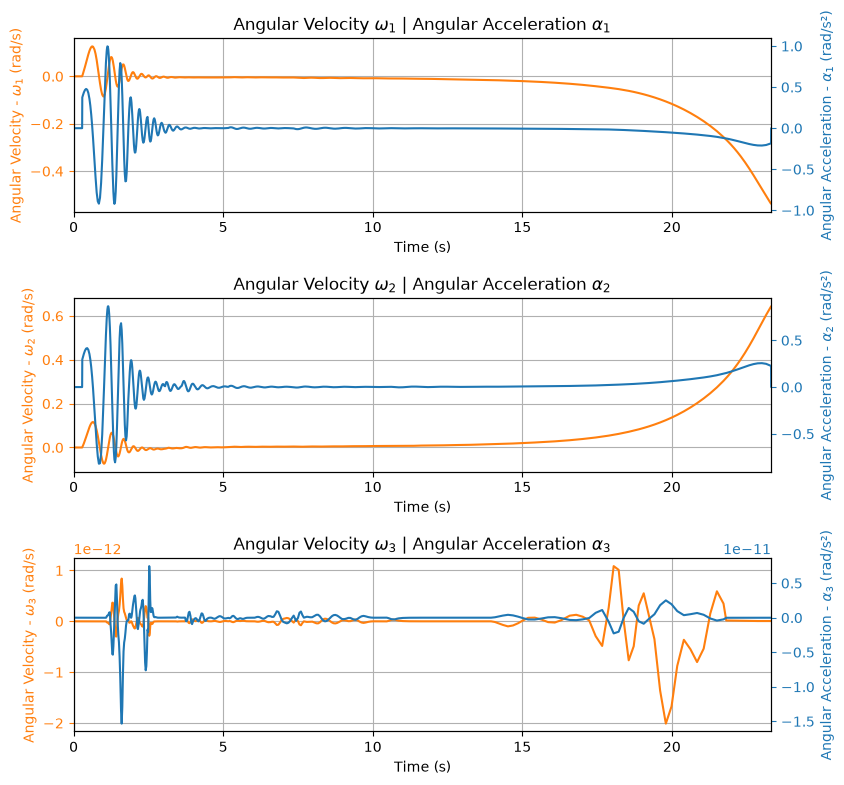



Aerodynamic Forces Plots



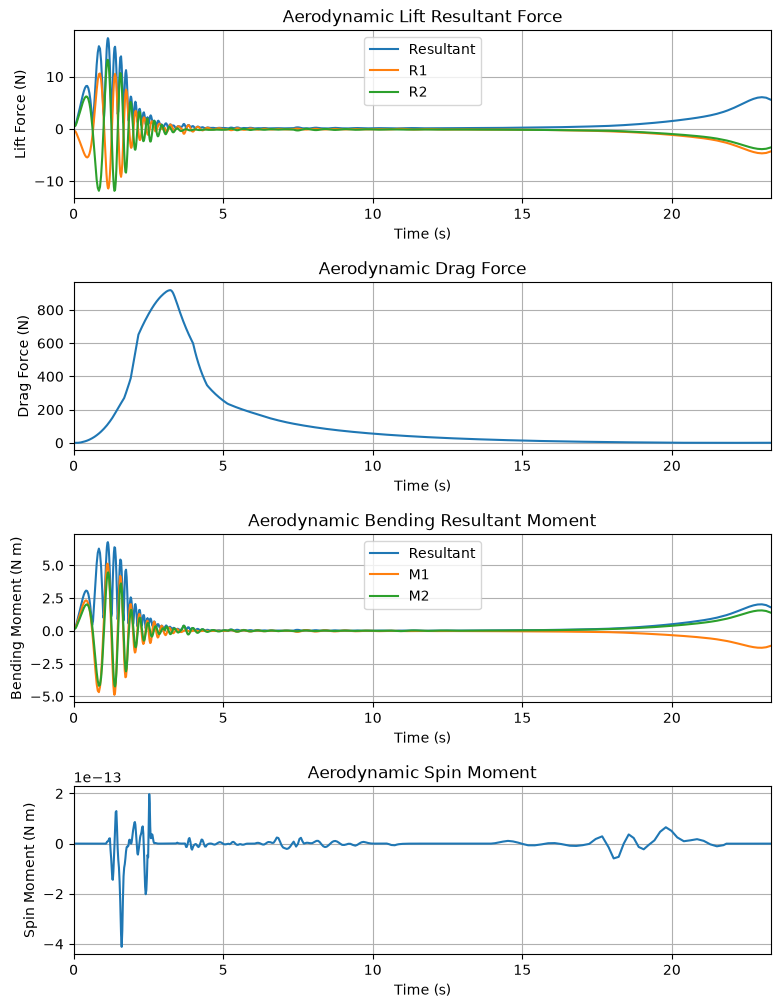

Rail button height not defined. Skipping bending moment plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



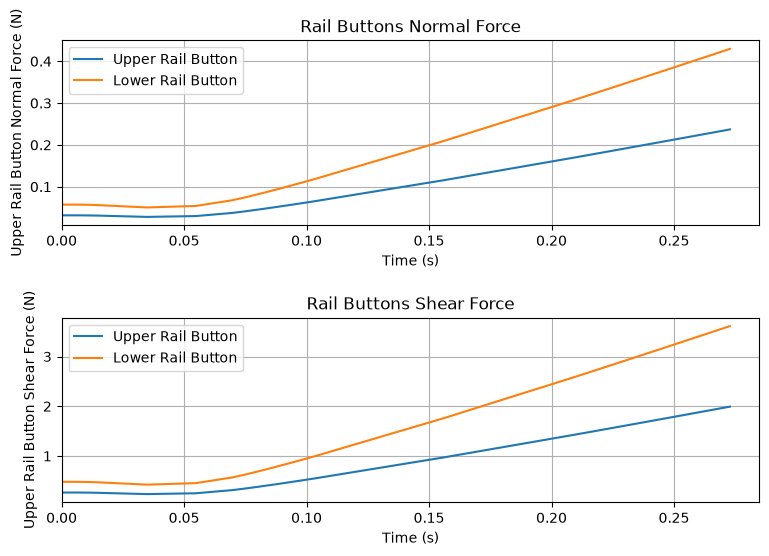



Trajectory Energy Plots



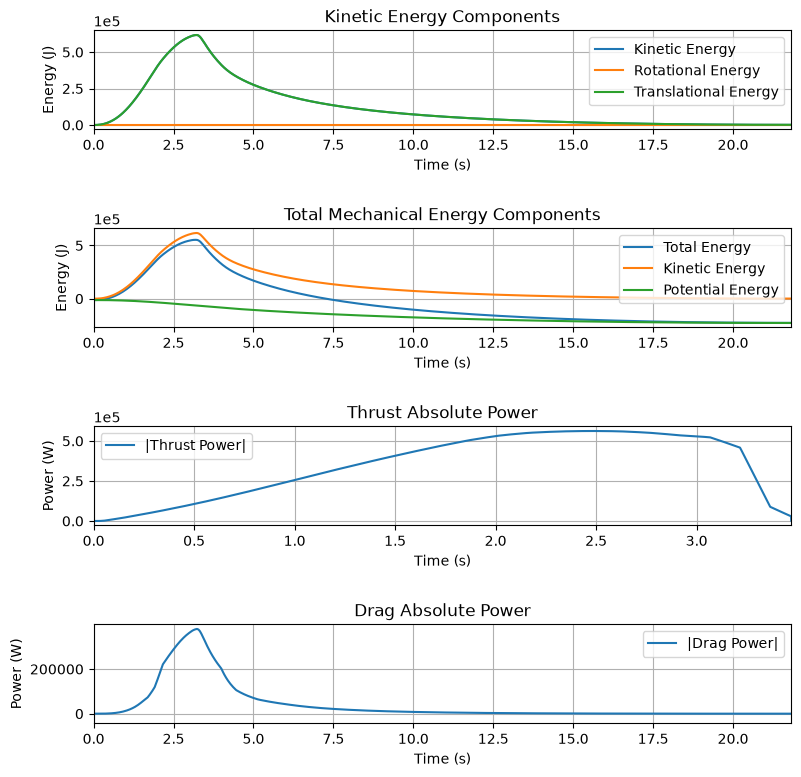



Trajectory Fluid Mechanics Plots



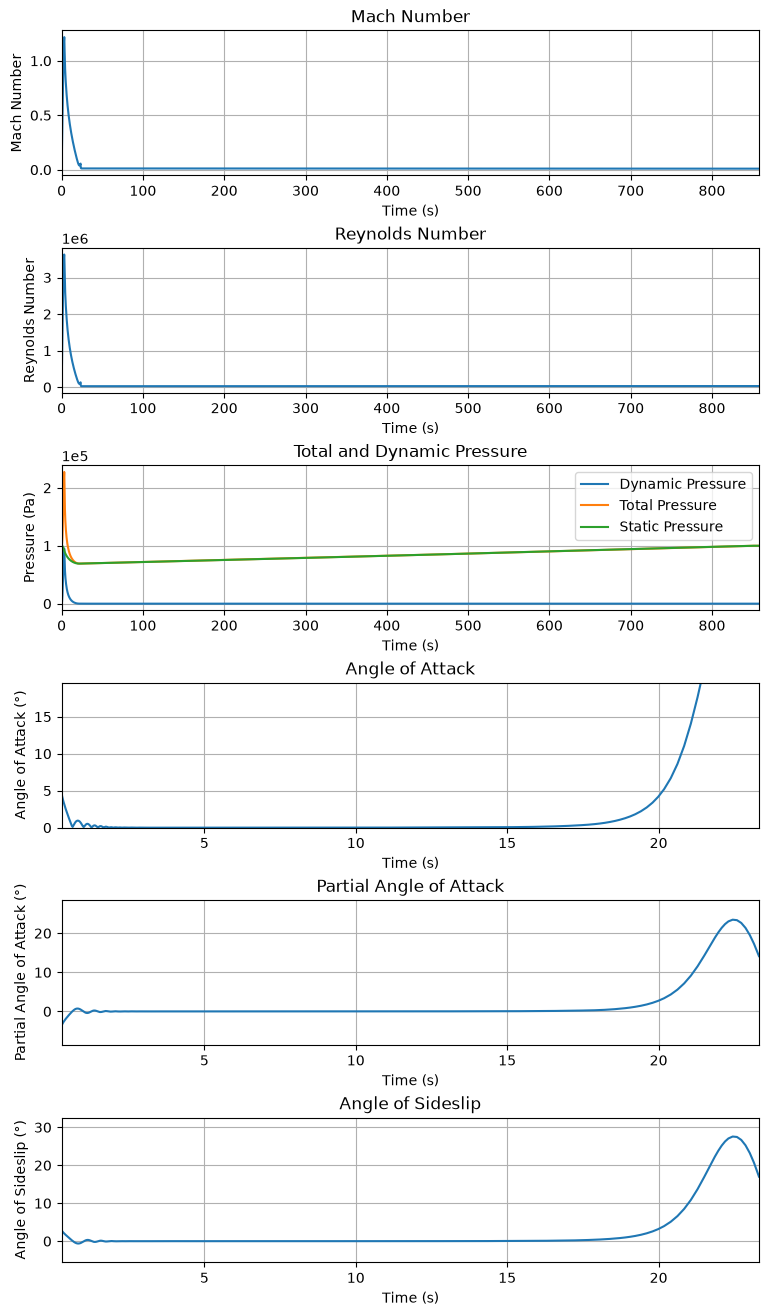



Trajectory Stability and Control Plots



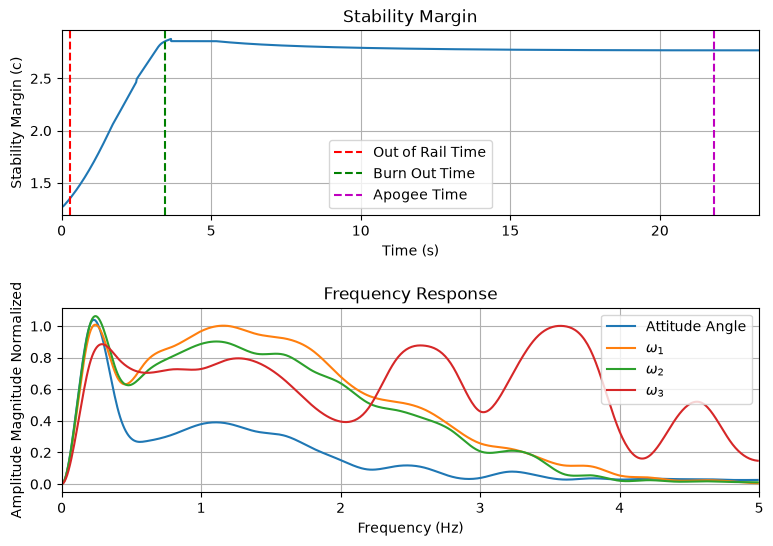



Rocket and Parachute Pressure Plots



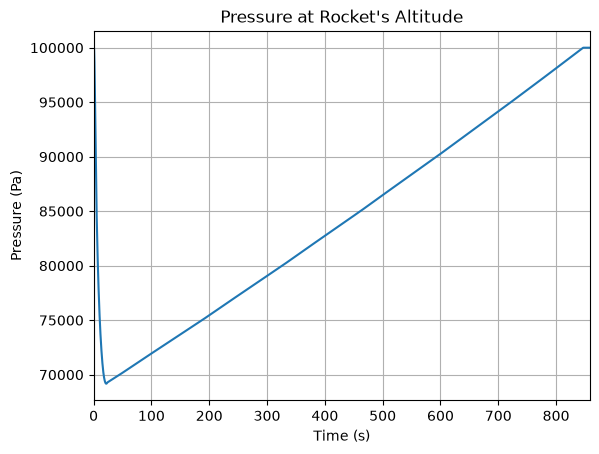

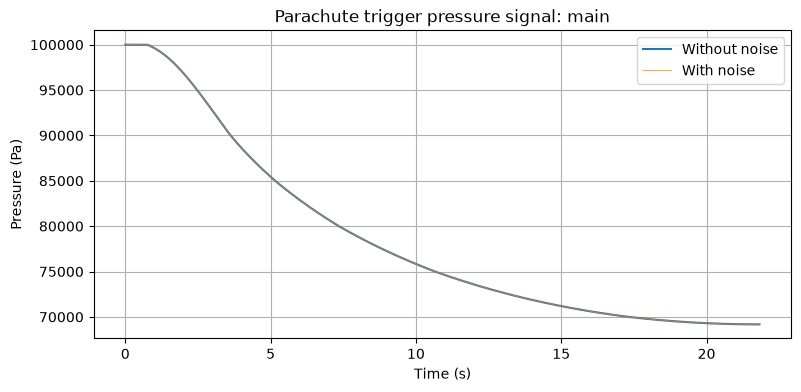


Apogee State

Apogee Time: 21.816 s
Apogee Altitude: 3233.501 m (ASL) | 3091.915 m (AGL)
Apogee Freestream Speed: 13.028 m/s
Apogee X position: 215.993 m
Apogee Y position: 429.944 m
Apogee latitude: 39.4372004°
Apogee longitude: -8.2944843°


In [160]:
test_flight = Flight(
    rocket=proto1, environment=env, rail_length=5.2, inclination=85, heading=0, max_time=1200
    )
test_flight.prints.maximum_values()
test_flight.all_info()
test_flight.prints.apogee_conditions()